# GECA Radar | Exploración de datos Steam + Twitch

Notebook diseñado para la base **`state/geca_twitch.sqlite3`** del proyecto **GECA Twitch Transaccional**. Permite explorar juegos, coincidencias, transmisiones, videos, clips, recepción de Steam y métricas de atención. **No necesita 14 días de historial para mostrar registros existentes.**

> Ejecuta el notebook desde la raíz del proyecto en VS Code con el kernel Conda `geca-twitch`. No utiliza credenciales ni llama a Twitch: solo lee la base SQLite local.

## 1. Configuración y conexión segura
Detecta la raíz del proyecto desde el directorio de trabajo o sus padres. Si la base todavía no existe, muestra un mensaje y **no crea una base vacía**.

In [1]:
from pathlib import Path
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.max_columns', 50)
pd.set_option('display.max_colwidth', 75)
pd.set_option('display.width', 160)

# Cambia esta ruta solo si el notebook está fuera del repositorio:
DB_OVERRIDE = None  # Ejemplo: r"C:\Users\pc\Desktop\github\geca_twitch\state\geca_twitch.sqlite3"

if DB_OVERRIDE:
    DB_PATH = Path(DB_OVERRIDE).expanduser().resolve()
else:
    candidates = [Path.cwd(), *Path.cwd().parents]
    root = next((p for p in candidates if (p / 'state' / 'geca_twitch.sqlite3').is_file()), None)
    DB_PATH = (root / 'state' / 'geca_twitch.sqlite3') if root else Path.cwd() / 'state' / 'geca_twitch.sqlite3'

print('Base:', DB_PATH)
if not DB_PATH.is_file():
    raise FileNotFoundError('No existe la base SQLite. Ejecuta primero la ingesta o configura DB_OVERRIDE.')

# Abrir solo lectura para evitar modificaciones accidentales
conn = sqlite3.connect(f'file:{DB_PATH.as_posix()}?mode=ro', uri=True)
print('Conexión SQLite establecida (solo lectura).')

Base: C:\Users\pc\Desktop\github\geca_twitch\state\geca_twitch.sqlite3
Conexión SQLite establecida (solo lectura).


## 2. Tablas disponibles y número de registros

In [2]:
tablas = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table' AND name NOT LIKE 'sqlite_%' ORDER BY name", conn)['name'].tolist()
resumen = pd.DataFrame([{'tabla': t, 'registros': conn.execute(f'SELECT COUNT(*) FROM "{t}"').fetchone()[0]} for t in tablas])
display(resumen)
print('Tablas encontradas:', len(tablas))

def leer_tabla(tabla, limite=1000):
    if tabla not in tablas:
        print(f'No existe la tabla {tabla!r}. Disponibles: {tablas}')
        return pd.DataFrame()
    if limite is None:
        return pd.read_sql_query(f'SELECT * FROM "{tabla}"', conn)
    return pd.read_sql_query(f'SELECT * FROM "{tabla}" LIMIT ?', conn, params=(int(limite),))


,tabla,registros
0,attention_alerts,0
1,clip_observations,155
2,daily_metrics,150
3,game_matches,467
4,game_snapshots,150
5,match_candidates,27
6,runs,1
7,steam_games,997
8,stream_snapshots,136
9,twitch_clips,155


Tablas encontradas: 13


## 3. Catálogo de juegos de Steam
Muestra el catálogo completo o una muestra, según los registros existentes.

In [3]:
df_steam = leer_tabla('steam_games', limite=None)
print('Juegos Steam:', len(df_steam))
if not df_steam.empty:
    columnas = [c for c in ['steam_appid','steam_name','release_date','reviews_total','reviews_positive','reviews_negative'] if c in df_steam]
    display(df_steam[columnas].head(30))

Juegos Steam: 997


,steam_appid,steam_name,release_date,reviews_total,reviews_positive,reviews_negative
0,5027770,1.44MB RESCUE,3 NOV 2026,0,0,0
1,4962590,100 Hidden Relics,5 NOV 2026,0,0,0
2,5136450,100K ZOMBIES,5 NOV 2026,0,0,0
3,4099810,1999TOKOYO Building,9 NOV 2026,0,0,0
4,4718050,1daYs,5 NOV 2026,0,0,0
5,5113890,2in1,10 NOV 2026,0,0,0
6,5110170,50-50-50,3 NOV 2026,0,0,0
7,5465990,A Cat Lived Here,8 NOV 2026,0,0,0
8,5243280,A Game About Picking Fruits,4 NOV 2026,0,0,0
9,5099920,A Little Faraway,5 NOV 2026,0,0,0


## 4. Juegos encontrados en Twitch

In [4]:
df_twitch = leer_tabla('twitch_games', limite=None)
print('Juegos Twitch:', len(df_twitch))
if not df_twitch.empty:
    columnas = [c for c in ['twitch_game_id','twitch_name','discovered_via','updated_utc'] if c in df_twitch]
    display(df_twitch[columnas].head(30))

Juegos Twitch: 572


,twitch_game_id,twitch_name,discovered_via,updated_utc
0,1822779899,Escape: The Cabin,steam_exact,2026-11-06T12:01:51Z
1,1299139309,Annum Crossroads,steam_exact,2026-11-06T12:01:51Z
2,1209875185,Little Lands,steam_exact,2026-11-06T12:01:51Z
3,973158857,Constellations,steam_exact,2026-11-06T12:01:51Z
4,635265230,Undead Development 2,steam_exact,2026-11-06T12:01:51Z
5,825569505,Demon Source,steam_exact,2026-11-06T12:01:51Z
6,447807617,Kingslayers,steam_exact,2026-11-06T12:01:51Z
7,1181081004,The House Before,steam_exact,2026-11-06T12:01:51Z
8,1402571474,Entropic Decay,steam_exact,2026-11-06T12:01:51Z
9,1681699018,Midwest 90: Rapid City,steam_exact,2026-11-06T12:01:51Z


## 5. Cruce de identidades Steam ↔ Twitch
`matched`, `ambiguous` y `unmatched` describen el estado del emparejamiento, **no** la calidad del juego.

In [5]:
if {'steam_games','game_matches','twitch_games'}.issubset(tablas):
    df_matches = pd.read_sql_query("""
        SELECT s.steam_appid, s.steam_name, s.release_date,
               m.twitch_game_id, t.twitch_name,
               m.confidence, m.status, m.method, m.checked_utc
        FROM steam_games s
        LEFT JOIN game_matches m ON m.steam_appid = s.steam_appid
        LEFT JOIN twitch_games t ON t.twitch_game_id = m.twitch_game_id
        ORDER BY s.steam_name
    """, conn)
    display(df_matches.head(40))
    display(df_matches['status'].fillna('sin evaluar').value_counts(dropna=False).rename_axis('estado').reset_index(name='juegos'))
else:
    df_matches = pd.DataFrame()
    print('Aún no hay tablas suficientes para realizar el cruce.')

,steam_appid,steam_name,release_date,twitch_game_id,twitch_name,confidence,status,method,checked_utc
0,5027770,1.44MB RESCUE,3 NOV 2026,1567880359,1.44MB RESCUE,1.0,matched,exact,2026-11-06T12:01:51Z
1,4962590,100 Hidden Relics,5 NOV 2026,1810435288,100 Hidden Relics,1.0,matched,exact,2026-11-06T12:01:51Z
2,5136450,100K ZOMBIES,5 NOV 2026,NaN,NaN,NaN,NaN,NaN,NaN
3,4099810,1999TOKOYO Building,9 NOV 2026,NaN,NaN,NaN,NaN,NaN,NaN
4,4718050,1daYs,5 NOV 2026,1206242732,1daYs,1.0,matched,exact,2026-11-06T12:01:51Z
5,5113890,2in1,10 NOV 2026,961880222,2in1,1.0,matched,exact,2026-11-06T12:01:51Z
6,5110170,50-50-50,3 NOV 2026,NaN,NaN,NaN,NaN,NaN,NaN
7,5465990,A Cat Lived Here,8 NOV 2026,NaN,NaN,NaN,NaN,NaN,NaN
8,5243280,A Game About Picking Fruits,4 NOV 2026,2129910557,A Game About Picking Fruits,1.0,matched,exact,2026-11-06T12:01:51Z
9,5099920,A Little Faraway,5 NOV 2026,1574599213,A Little Faraway,1.0,matched,exact,2026-11-06T12:01:51Z


,estado,juegos
0,sin evaluar,530
1,matched,447
2,unmatched,13
3,ambiguous,7


## 6. Juegos exclusivos de Twitch (sin coincidencia confirmada en Steam)

In [6]:
if {'twitch_games','game_matches'}.issubset(tablas):
    df_twitch_only = pd.read_sql_query("""
        SELECT t.twitch_game_id, t.twitch_name, t.discovered_via, t.updated_utc
        FROM twitch_games t
        WHERE NOT EXISTS (
            SELECT 1 FROM game_matches m
            WHERE m.twitch_game_id=t.twitch_game_id AND m.status='matched'
        ) ORDER BY t.twitch_name
    """, conn)
    print('Sin coincidencia confirmada:', len(df_twitch_only))
    display(df_twitch_only.head(50))
else:
    df_twitch_only = pd.DataFrame()
    print('Datos todavía insuficientes.')

Sin coincidencia confirmada: 125


,twitch_game_id,twitch_name,discovered_via,updated_utc
0,771448419,AION 2,twitch_top,2026-11-06T12:01:51Z
1,464339927,ARC Raiders,twitch_top,2026-11-06T12:01:51Z
2,509659,ASMR,twitch_top,2026-11-06T12:01:51Z
3,417528,Albion Online,twitch_top,2026-11-06T12:01:51Z
4,499973,Always On,twitch_top,2026-11-06T12:01:51Z
5,272263131,"Animals, Aquariums, and Zoos",twitch_top,2026-11-06T12:01:51Z
6,1637021799,Anno 117: Pax Romana,twitch_top,2026-11-06T12:01:51Z
7,511224,Apex Legends,twitch_top,2026-11-06T12:01:51Z
8,401587136,Arena Breakout: Infinite,twitch_top,2026-11-06T12:01:51Z
9,509660,Art,twitch_top,2026-11-06T12:01:51Z


## 7. Observaciones individuales de streams
Cada fila representa una transmisión en un instante de captura. **No se deben sumar espectadores de distintos instantes como si fueran usuarios únicos.**

In [7]:
if 'stream_snapshots' in tablas:
    df_streams = pd.read_sql_query("""
        SELECT s.capture_id, s.stream_id, s.twitch_game_id, t.twitch_name,
               s.captured_utc, s.user_name, s.title, s.language,
               s.viewer_count, s.started_at
        FROM stream_snapshots s
        LEFT JOIN twitch_games t ON t.twitch_game_id=s.twitch_game_id
        ORDER BY s.captured_utc DESC, s.viewer_count DESC LIMIT 300
    """, conn)
    print('Muestra de snapshots de transmisiones:', len(df_streams))
    display(df_streams.head(40))
else:
    df_streams = pd.DataFrame()
    print('No existe stream_snapshots todavía.')

Muestra de snapshots de transmisiones: 136


,capture_id,stream_id,twitch_game_id,twitch_name,captured_utc,user_name,title,language,viewer_count,started_at
0,ad26eba18499436486f1d309c9e7de9c-1:1582778527,316745482867,1582778527,Annihilated,2026-11-06T12:03:12Z,富士川マッケ,勇者パーティーはぜんめつしました 体験版配信,ja,1,2026-11-06T10:28:46Z
1,ad26eba18499436486f1d309c9e7de9c-1:1514404776,319288017254,1514404776,Potato Please,2026-11-06T12:03:07Z,hc_diZee,🔴Für die Horde! Es müssen Kartoffeln ran - !yazio !holy !srs,de,141,2026-11-06T08:57:38Z
2,ad26eba18499436486f1d309c9e7de9c-1:1514404776,317209452630,1514404776,Potato Please,2026-11-06T12:03:07Z,ChannelRion,"Чилим, щупаем картошечку | !1080",ru,64,2026-11-06T11:05:55Z
3,ad26eba18499436486f1d309c9e7de9c-1:1514404776,316687486322,1514404776,Potato Please,2026-11-06T12:03:07Z,紅乱華,雑談しながらじゃがいもの皮剝き,ja,34,2026-11-06T09:39:22Z
4,ad26eba18499436486f1d309c9e7de9c-1:1514404776,317209435606,1514404776,Potato Please,2026-11-06T12:03:07Z,baksash,Я ГЛУХОЙ СТРИМ ЛЮБОЙ ИГРЫ / АНИМЕ ФИЛЬМ,ru,30,2026-11-06T11:02:18Z
5,ad26eba18499436486f1d309c9e7de9c-1:1514404776,317256103380,1514404776,Potato Please,2026-11-06T12:03:07Z,MahiruChan,[МАХИТОН] День 82: Картофельное свидание! | !хорнибокс !boosty !discord,ru,24,2026-11-06T09:09:02Z
6,ad26eba18499436486f1d309c9e7de9c-1:1514404776,316222429011,1514404776,Potato Please,2026-11-06T12:03:07Z,ClarkPlaysGamez,"[18+] BDAY STREAM | Reacts, Potatoes and a surprise late, i dont know w...",en,23,2026-11-06T09:05:35Z
7,ad26eba18499436486f1d309c9e7de9c-1:1514404776,319288732390,1514404776,Potato Please,2026-11-06T12:03:07Z,Senhoshi,✨(•‾⌣‾•)و ̑̑♡ Lord of the Fries: The Fellowship of the Peel | 18+ | !mg...,en,18,2026-11-06T10:28:47Z
8,ad26eba18499436486f1d309c9e7de9c-1:1514404776,316272852201,1514404776,Potato Please,2026-11-06T12:03:07Z,MorikaToto,[18+] [中/EN] | New Outfit Fundraising D1 !! | First: @💛| !commands,en,16,2026-11-06T11:06:09Z
9,ad26eba18499436486f1d309c9e7de9c-1:1514404776,318250139363,1514404776,Potato Please,2026-11-06T12:03:07Z,TatoTourist,:potato: A Potato Peeling Potatoes until I can't peel any more! | !disc...,en,7,2026-11-06T11:21:18Z


## 8. Fotografías de atención por videojuego
`viewers_observed` es la suma observada en una misma captura; `streams_complete` indica si esa captura cubrió las transmisiones conforme al límite de la extracción.

Fotografías (muestra): 150


,twitch_game_id,twitch_name,captured_utc,viewers_observed,streams_observed,streams_complete
0,1586232318,Kachow Kart Racing,2026-11-06T12:03:14Z,0,0,1
1,1592842270,UBAI Ending,2026-11-06T12:03:14Z,0,0,1
2,1585817791,Patience Balls,2026-11-06T12:03:13Z,0,0,1
3,1582778527,Annihilated,2026-11-06T12:03:12Z,1,1,1
4,1574599213,A Little Faraway,2026-11-06T12:03:12Z,0,0,1
5,1567880359,1.44MB RESCUE,2026-11-06T12:03:11Z,0,0,1
6,1568703936,Rebirth TD,2026-11-06T12:03:11Z,0,0,1
7,1533172867,Don Bradman Cricket Jr,2026-11-06T12:03:10Z,0,0,1
8,1558217415,Low Earth Orbit Adventures,2026-11-06T12:03:10Z,0,0,1
9,1565682077,Night Cart: The Immortal Plague,2026-11-06T12:03:10Z,0,0,1


,twitch_name,captured_utc,viewers_observed,streams_observed,streams_complete
149,Football Manager 27,2026-11-06T12:01:57Z,2028,31,1
63,ArcheAge Chronicles,2026-11-06T12:02:40Z,1110,55,1
66,Cozy Game Restoration,2026-11-06T12:02:38Z,456,6,1
13,Potato Please,2026-11-06T12:03:07Z,414,26,1
98,Godzilla: Destroy All Monsters Melee Remastered,2026-11-06T12:02:23Z,22,7,1
22,Theos: Cities of Myth,2026-11-06T12:03:02Z,14,3,1
70,Football Academy Simulator,2026-11-06T12:02:36Z,10,1,1
32,Find The Needle,2026-11-06T12:02:56Z,9,2,1
41,Spellchain,2026-11-06T12:02:51Z,5,1,1
25,Dominus Gladiatus,2026-11-06T12:03:00Z,3,2,1


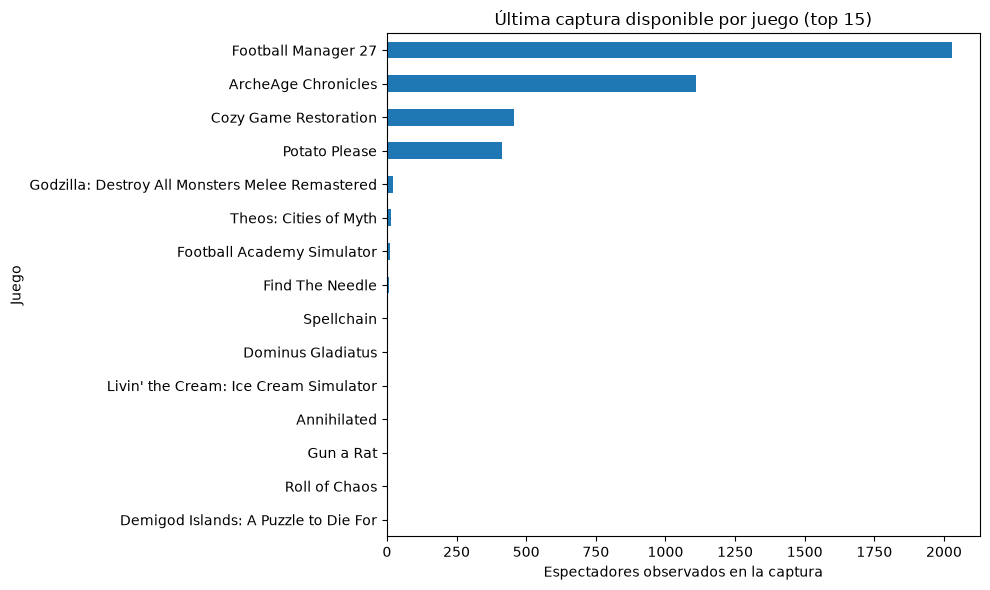

In [8]:
if 'game_snapshots' in tablas:
    df_snapshots = pd.read_sql_query("""
        SELECT gs.twitch_game_id, t.twitch_name, gs.captured_utc,
               gs.viewers_observed, gs.streams_observed, gs.streams_complete
        FROM game_snapshots gs LEFT JOIN twitch_games t
          ON gs.twitch_game_id=t.twitch_game_id
        ORDER BY gs.captured_utc DESC, gs.viewers_observed DESC LIMIT 500
    """, conn)
    print('Fotografías (muestra):', len(df_snapshots))
    display(df_snapshots.head(40))
    if not df_snapshots.empty:
        top = (df_snapshots.sort_values('captured_utc')
               .groupby(['twitch_game_id','twitch_name'], dropna=False, as_index=False).tail(1)
               .sort_values('viewers_observed', ascending=False).head(15))
        display(top[['twitch_name','captured_utc','viewers_observed','streams_observed','streams_complete']])
        top.sort_values('viewers_observed').plot.barh(x='twitch_name', y='viewers_observed', legend=False, figsize=(10,6), title='Última captura disponible por juego (top 15)')
        plt.xlabel('Espectadores observados en la captura'); plt.ylabel('Juego'); plt.tight_layout(); plt.show()
else:
    df_snapshots = pd.DataFrame()
    print('No hay tabla game_snapshots.')

## 9. Videos y sus observaciones de visualizaciones

In [9]:
df_videos = leer_tabla('twitch_videos', limite=200)
df_video_obs = leer_tabla('video_observations', limite=200)
print('Videos (muestra):',len(df_videos),'| observaciones (muestra):',len(df_video_obs))
if not df_videos.empty:
    display(df_videos[[c for c in ['video_id','twitch_game_id','title','language','created_at','url','last_seen_utc'] if c in df_videos]].head(30))
if not df_video_obs.empty:
    display(df_video_obs.head(20))

Videos (muestra): 200 | observaciones (muestra): 200


,video_id,twitch_game_id,title,language,created_at,url,last_seen_utc
0,2921059626,1000178598,🔥FM27: The Verdict🔥 SC Braga - Type !save,en,2026-11-06T12:00:06Z,https://www.twitch.tv/videos/2921059626,2026-11-06T12:01:57Z
1,2921058280,1000178598,I GOT SACKED... now i'm the Leicester manager 🦊 | !logi | !insta | !gpo...,en,2026-11-06T11:57:36Z,https://www.twitch.tv/videos/2921058280,2026-11-06T12:01:57Z
2,2921052927,1000178598,SHRIMPERS TO GLORY|FM 27|Happy FRIDAY| !Discord !lurk,en,2026-11-06T11:45:44Z,https://www.twitch.tv/videos/2921052927,2026-11-06T12:01:57Z
3,2921041019,1000178598,TRANSFERS & PLAYOFF PUSH AT LUTON! 🧡 | !prime !youtube,en,2026-11-06T11:16:58Z,https://www.twitch.tv/videos/2921041019,2026-11-06T12:01:57Z
4,2921036984,1000178598,SUBATHON !! | ACHIEVMENT THROUGH UNITY | HAWFC | !SUBATHON| ACCIES RTG ...,en,2026-11-06T11:06:47Z,https://www.twitch.tv/videos/2921036984,2026-11-06T12:01:57Z
5,2921034646,1000178598,SAVING SPURS - MEGA STREAM - SEASON 2 - PRE ORDER !FM27,en,2026-11-06T11:01:27Z,https://www.twitch.tv/videos/2921034646,2026-11-06T12:01:57Z
6,2921034492,1000178598,CHIMARRÃO & FOOTBALL MANAGER | VEM PRA RESENHA,pt,2026-11-06T11:01:10Z,https://www.twitch.tv/videos/2921034492,2026-11-06T12:01:57Z
7,2921028823,1000178598,fm27 blackpool,el,2026-11-06T10:48:14Z,https://www.twitch.tv/videos/2921028823,2026-11-06T12:01:57Z
8,2921018042,1000178598,"🇸🇮 Nk Maribor 🇸🇮 - Team i got already sacked twice from , let's see if ...",en,2026-11-06T10:18:32Z,https://www.twitch.tv/videos/2921018042,2026-11-06T12:01:57Z
9,2921016217,1000178598,⚽DOVER ATHLETIC ⚽// Árbitro el niño !!,es,2026-11-06T10:13:25Z,https://www.twitch.tv/videos/2921016217,2026-11-06T12:01:57Z


,video_id,capture_id,captured_utc,view_count
0,2921059626,ad26eba18499436486f1d309c9e7de9c-1:1000178598,2026-11-06T12:01:57Z,0
1,2921058280,ad26eba18499436486f1d309c9e7de9c-1:1000178598,2026-11-06T12:01:57Z,0
2,2921052927,ad26eba18499436486f1d309c9e7de9c-1:1000178598,2026-11-06T12:01:57Z,0
3,2921041019,ad26eba18499436486f1d309c9e7de9c-1:1000178598,2026-11-06T12:01:57Z,1
4,2921036984,ad26eba18499436486f1d309c9e7de9c-1:1000178598,2026-11-06T12:01:57Z,0
5,2921034646,ad26eba18499436486f1d309c9e7de9c-1:1000178598,2026-11-06T12:01:57Z,13
6,2921034492,ad26eba18499436486f1d309c9e7de9c-1:1000178598,2026-11-06T12:01:57Z,0
7,2921028823,ad26eba18499436486f1d309c9e7de9c-1:1000178598,2026-11-06T12:01:57Z,0
8,2921018042,ad26eba18499436486f1d309c9e7de9c-1:1000178598,2026-11-06T12:01:57Z,0
9,2921016217,ad26eba18499436486f1d309c9e7de9c-1:1000178598,2026-11-06T12:01:57Z,0


## 10. Clips y sus observaciones de visualizaciones

In [10]:
df_clips = leer_tabla('twitch_clips', limite=200)
df_clip_obs = leer_tabla('clip_observations', limite=200)
print('Clips (muestra):',len(df_clips),'| observaciones (muestra):',len(df_clip_obs))
if not df_clips.empty:
    display(df_clips[[c for c in ['clip_id','twitch_game_id','title','language','created_at','url','last_seen_utc'] if c in df_clips]].head(30))
if not df_clip_obs.empty:
    display(df_clip_obs.head(20))

Clips (muestra): 155 | observaciones (muestra): 155


,clip_id,twitch_game_id,title,language,created_at,url,last_seen_utc
0,BitterMoistSandpiperPogChamp-epFETs63lm6yhreA,1000178598,Technique is class,en,2026-11-06T04:45:33Z,https://www.twitch.tv/ziggurath/clip/BitterMoistSandpiperPogChamp-epFET...,2026-11-06T12:01:57Z
1,TsundereFancyCoyoteDoggo-9PYewVi7qMUKaDUJ,1000178598,TIRADA DE CABLE Y EL MONO SE LAS PIRA!!,es,2026-11-06T08:30:31Z,https://www.twitch.tv/locomotronix/clip/TsundereFancyCoyoteDoggo-9PYewV...,2026-11-06T12:01:57Z
2,BadCarefulPangolinPJSalt-P1PEb2n4Gu5KCbR3,1000178598,FM’d Leipzig😭,en,2026-11-06T11:04:32Z,https://www.twitch.tv/thefmjunkie/clip/BadCarefulPangolinPJSalt-P1PEb2n...,2026-11-06T12:01:57Z
3,CaringSwissSpaghettiDBstyle-VQA57wGlvO6ovPzt,1000178598,The FMing of the centuary,en,2026-11-06T11:06:13Z,https://www.twitch.tv/thefmjunkie/clip/CaringSwissSpaghettiDBstyle-VQA5...,2026-11-06T12:01:57Z
4,BitterHonestLeopardBudStar-qq9z_j8STJqmKZlC,1000178598,Attributes or form?,en,2026-11-06T08:55:00Z,https://www.twitch.tv/loadfm/clip/BitterHonestLeopardBudStar-qq9z_j8STJ...,2026-11-06T12:01:57Z
5,SwissCleverMonkeyFeelsBadMan-Gz2_h3cs2Z18MylE,1000178598,Everyone's contributing now!,en,2026-11-06T08:57:15Z,https://www.twitch.tv/loadfm/clip/SwissCleverMonkeyFeelsBadMan-Gz2_h3cs...,2026-11-06T12:01:57Z
6,VenomousBombasticMushroomBudStar-e5DrVDoC6bCYvmni,1000178598,He Just STOPS....,en,2026-11-06T08:49:02Z,https://www.twitch.tv/loadfm/clip/VenomousBombasticMushroomBudStar-e5Dr...,2026-11-06T12:01:57Z
7,ObedientFlirtyRaisinPanicVis-7nbcHK6IWU730D6w,1000178598,Just a little bit offside 😂,en,2026-11-06T04:11:17Z,https://www.twitch.tv/jordanchimes/clip/ObedientFlirtyRaisinPanicVis-7n...,2026-11-06T12:01:57Z
8,CulturedMiniatureDinosaurHumbleLife-skvqEGaAl45YGy2i,1000178598,FM27 The Wave Save Season 1 | NWSL Women's Football,en,2026-11-06T04:08:24Z,https://www.twitch.tv/prophetmarginal/clip/CulturedMiniatureDinosaurHum...,2026-11-06T12:01:57Z
9,PatientShinyBadgerAsianGlow-rivNt8I-DLRee9z0,1000178598,FM27 The Wave Save Season 1 | NWSL Women's Football,en,2026-11-06T04:43:50Z,https://www.twitch.tv/prophetmarginal/clip/PatientShinyBadgerAsianGlow-...,2026-11-06T12:01:57Z


,clip_id,capture_id,captured_utc,view_count
0,BitterMoistSandpiperPogChamp-epFETs63lm6yhreA,ad26eba18499436486f1d309c9e7de9c-1:1000178598,2026-11-06T12:01:57Z,9
1,TsundereFancyCoyoteDoggo-9PYewVi7qMUKaDUJ,ad26eba18499436486f1d309c9e7de9c-1:1000178598,2026-11-06T12:01:57Z,4
2,BadCarefulPangolinPJSalt-P1PEb2n4Gu5KCbR3,ad26eba18499436486f1d309c9e7de9c-1:1000178598,2026-11-06T12:01:57Z,1
3,CaringSwissSpaghettiDBstyle-VQA57wGlvO6ovPzt,ad26eba18499436486f1d309c9e7de9c-1:1000178598,2026-11-06T12:01:57Z,1
4,BitterHonestLeopardBudStar-qq9z_j8STJqmKZlC,ad26eba18499436486f1d309c9e7de9c-1:1000178598,2026-11-06T12:01:57Z,1
5,SwissCleverMonkeyFeelsBadMan-Gz2_h3cs2Z18MylE,ad26eba18499436486f1d309c9e7de9c-1:1000178598,2026-11-06T12:01:57Z,1
6,VenomousBombasticMushroomBudStar-e5DrVDoC6bCYvmni,ad26eba18499436486f1d309c9e7de9c-1:1000178598,2026-11-06T12:01:57Z,1
7,ObedientFlirtyRaisinPanicVis-7nbcHK6IWU730D6w,ad26eba18499436486f1d309c9e7de9c-1:1000178598,2026-11-06T12:01:57Z,1
8,CulturedMiniatureDinosaurHumbleLife-skvqEGaAl45YGy2i,ad26eba18499436486f1d309c9e7de9c-1:1000178598,2026-11-06T12:01:57Z,1
9,PatientShinyBadgerAsianGlow-rivNt8I-DLRee9z0,ad26eba18499436486f1d309c9e7de9c-1:1000178598,2026-11-06T12:01:57Z,1


## 11. Recepción en Steam: reseñas positivas y negativas
Estos son datos de **Steam**, no un análisis de mensajes de chat de Twitch. El porcentaje solo se calcula cuando hay reseñas positivas y negativas disponibles.

In [11]:
if not df_steam.empty:
    df_recepcion = df_steam[[c for c in ['steam_appid','steam_name','reviews_positive','reviews_negative','reviews_total'] if c in df_steam]].copy()
    if {'reviews_positive','reviews_negative'}.issubset(df_recepcion):
        total = df_recepcion['reviews_positive'].fillna(0) + df_recepcion['reviews_negative'].fillna(0)
        df_recepcion['porcentaje_positivo_steam'] = (100 * df_recepcion['reviews_positive'] / total.where(total.gt(0))).round(2)
    display(df_recepcion.head(40))
else:
    print('Aún no hay información de reseñas Steam en SQLite.')

,steam_appid,steam_name,reviews_positive,reviews_negative,reviews_total,porcentaje_positivo_steam
0,5027770,1.44MB RESCUE,0,0,0,NaN
1,4962590,100 Hidden Relics,0,0,0,NaN
2,5136450,100K ZOMBIES,0,0,0,NaN
3,4099810,1999TOKOYO Building,0,0,0,NaN
4,4718050,1daYs,0,0,0,NaN
5,5113890,2in1,0,0,0,NaN
6,5110170,50-50-50,0,0,0,NaN
7,5465990,A Cat Lived Here,0,0,0,NaN
8,5243280,A Game About Picking Fruits,0,0,0,NaN
9,5099920,A Little Faraway,0,0,0,NaN


## 12. Agregados diarios y alertas GECA
No tener alertas durante los primeros 14 días completos de mediciones es esperado. Aquí se muestran los registros que existan.

In [12]:
df_daily = leer_tabla('daily_metrics', limite=1000)
df_alertas = leer_tabla('attention_alerts', limite=1000)
print('Filas de métricas diarias (muestra):',len(df_daily))
display(df_daily.head(30))
print('Filas de alertas (muestra):',len(df_alertas))
display(df_alertas.head(30))

Filas de métricas diarias (muestra): 150


,utc_day,twitch_game_id,snapshot_count,avg_viewers,max_viewers,avg_streams,streams_complete,new_videos,new_clips
0,2026-11-06,1000178598,1,2028.0,2028,31.0,1,46,28
1,2026-11-06,1004036127,1,0.0,0,0.0,1,0,0
2,2026-11-06,1007597169,1,0.0,0,0.0,1,0,0
3,2026-11-06,1010523319,1,0.0,0,0.0,1,0,0
4,2026-11-06,1011991203,1,0.0,0,0.0,1,0,0
5,2026-11-06,1015558473,1,0.0,0,0.0,1,0,0
6,2026-11-06,1015838409,1,0.0,0,0.0,1,0,0
7,2026-11-06,1031554177,1,0.0,0,0.0,1,0,0
8,2026-11-06,1033324902,1,0.0,0,0.0,1,0,0
9,2026-11-06,1043071291,1,0.0,0,0.0,1,1,0


Filas de alertas (muestra): 0


,evaluated_utc_day,twitch_game_id,prior_avg,recent_avg,delta_viewers,growth_pct,eligible


## 13. Explorar un videojuego concreto
Escribe parte del nombre y ejecuta la celda. Esto muestra su identidad y la evolución temporal de espectadores, cuando existan observaciones.

In [13]:
BUSCAR_JUEGO = ''  # Ejemplo: 'Hollow Knight' (dejar vacío muestra ejemplos)
if not df_twitch.empty:
    encontrados = df_twitch[df_twitch['twitch_name'].str.contains(BUSCAR_JUEGO, case=False, na=False, regex=False)]
    display(encontrados[[c for c in ['twitch_game_id','twitch_name','discovered_via'] if c in encontrados]].head(20))
    if not encontrados.empty and 'game_snapshots' in tablas:
        gid = str(encontrados.iloc[0]['twitch_game_id'])
        serie = pd.read_sql_query("""
            SELECT captured_utc, viewers_observed, streams_observed, streams_complete
            FROM game_snapshots WHERE twitch_game_id=? ORDER BY captured_utc
        """, conn, params=(gid,))
        display(serie.tail(30))
        if not serie.empty:
            serie['captured_utc'] = pd.to_datetime(serie['captured_utc'], utc=True, errors='coerce')
            serie.plot(x='captured_utc', y='viewers_observed', figsize=(11,4), legend=False, marker='o', title=f'Espectadores observados — {encontrados.iloc[0]["twitch_name"]}')
            plt.xlabel('Fecha (UTC)'); plt.ylabel('Espectadores observados'); plt.tight_layout(); plt.show()
else:
    print('No hay videojuegos Twitch para buscar.')

,twitch_game_id,twitch_name,discovered_via
0,1822779899,Escape: The Cabin,steam_exact
1,1299139309,Annum Crossroads,steam_exact
2,1209875185,Little Lands,steam_exact
3,973158857,Constellations,steam_exact
4,635265230,Undead Development 2,steam_exact
5,825569505,Demon Source,steam_exact
6,447807617,Kingslayers,steam_exact
7,1181081004,The House Before,steam_exact
8,1402571474,Entropic Decay,steam_exact
9,1681699018,Midwest 90: Rapid City,steam_exact


,captured_utc,viewers_observed,streams_observed,streams_complete


## 14. Historial y estado de las ejecuciones

In [14]:
df_runs = leer_tabla('runs', limite=100)
if not df_runs.empty and 'started_utc' in df_runs:
    df_runs = df_runs.sort_values('started_utc', ascending=False)
display(df_runs.head(30))

,run_id,started_utc,finished_utc,status,games_attempted,games_succeeded,games_failed,error_summary
0,ad26eba18499436486f1d309c9e7de9c-1,2026-11-06T12:01:51Z,2026-11-06T12:03:14Z,success,150,150,0,[]


## 15. Exportación opcional

Si quieres generar un Excel con muestras de cada tabla, activa `EXPORTAR_EXCEL = True`. Para exportar datos masivos, preferir CSV o Parquet en lugar de Excel.

In [15]:
EXPORTAR_EXCEL = False
if EXPORTAR_EXCEL:
    destino = DB_PATH.parent.parent / 'GECA_Twitch_exploracion.xlsx'
    with pd.ExcelWriter(destino, engine='openpyxl') as w:
        for tabla in tablas:
            df = leer_tabla(tabla, limite=50000)
            # Excel limita los nombres de hoja a 31 caracteres
            df.to_excel(w, sheet_name=tabla[:31], index=False)
    print('Excel exportado:', destino)
else:
    print('Exportación desactivada; cambia EXPORTAR_EXCEL a True para habilitarla.')

Exportación desactivada; cambia EXPORTAR_EXCEL a True para habilitarla.


## Consideraciones para interpretar la información

- **Steam y Twitch tienen identificadores distintos**; revisa `game_matches` antes de atribuir una transmisión a un juego Steam.
- **Viewers:** son observaciones de espectadores simultáneos, no usuarios únicos ni horas vistas.
- **Videos/clips:** sus observaciones de visualizaciones se guardan separadamente; no sumes capturas sucesivas como visualizaciones nuevas.
- **Sentimiento de jugadores:** esta versión de la base no contiene mensajes de chat, por lo que no calcula porcentajes positivos/negativos de Twitch. `reviews_positive` y `reviews_negative` corresponden a Steam.
- **Alertas:** requieren 14 días UTC completos con las seis franjas de captura y cumplimiento simultáneo de los umbrales de +500 espectadores y +50 %.
- **Si las tablas están vacías**, ejecuta primero `python -m geca_twitch.ingest` (con las credenciales configuradas) y luego `python -m geca_twitch.aggregate`.


In [16]:
conn.close()
print('Conexión cerrada.')

Conexión cerrada.
